# Train — InceptionNet v3

Trains and evaluates InceptionNet v3 with the tuned hyperparameters in `ARCH_HYPERPARAMS["inception_v3"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["inception_v3"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"InceptionNet v3: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

InceptionNet v3: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, target = 96)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

# The auxiliary classifier (training only) keeps a single Linear output layer.
model.AuxLogits.fc = nn.Linear(model.AuxLogits.fc.in_features, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[InceptionNet v3] Gradient accumulation: 6 micro-batches per optimizer step.


[InceptionNet v3] Epoch   1/100 | LR: 2.23e-04 | train loss 1.4511 acc 0.542 | val loss 0.9040 acc 0.699 *


[InceptionNet v3] Epoch   2/100 | LR: 2.23e-04 | train loss 1.1469 acc 0.729 | val loss 0.6133 acc 0.742 *


[InceptionNet v3] Epoch   3/100 | LR: 2.23e-04 | train loss 0.9334 acc 0.760 | val loss 0.7805 acc 0.633


[InceptionNet v3] Epoch   4/100 | LR: 2.23e-04 | train loss 0.8886 acc 0.744 | val loss 0.5699 acc 0.751 *


...

[InceptionNet v3] Epoch  20/100 | LR: 2.23e-04 | train loss 0.2256 acc 0.947 | val loss 0.7003 acc 0.808


[InceptionNet v3] Epoch  21/100 | LR: 2.23e-04 | train loss 0.2261 acc 0.946 | val loss 0.7198 acc 0.799


[InceptionNet v3] Epoch  22/100 | LR: 2.23e-04 | train loss 0.2161 acc 0.948 | val loss 0.6254 acc 0.825


[InceptionNet v3] Epoch  23/100 | LR: 2.23e-04 | train loss 0.1844 acc 0.961 | val loss 1.1512 acc 0.725


[InceptionNet v3] Epoch  24/100 | LR: 2.23e-04 | train loss 0.2777 acc 0.931 | val loss 0.8591 acc 0.786

[InceptionNet v3] No val loss improvement for 10 epochs, stopping at epoch 24.

[InceptionNet v3] Restored best checkpoint (val loss = 0.4962)


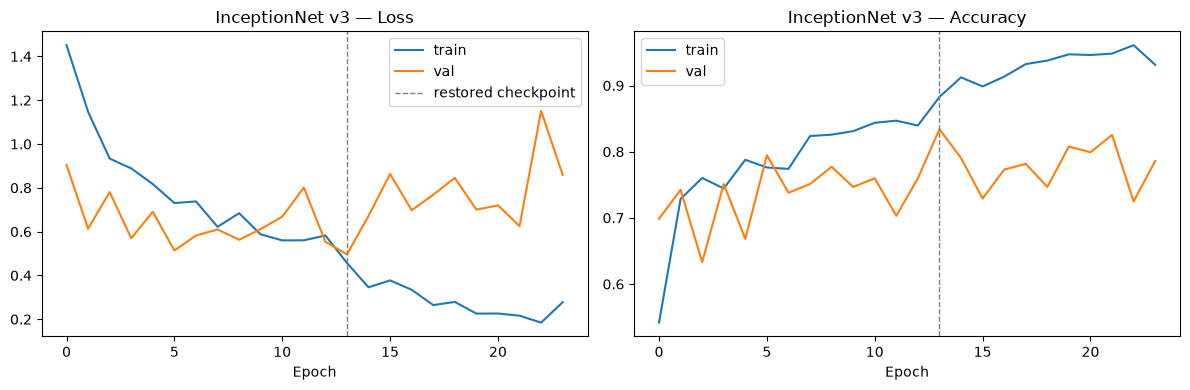

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "InceptionNet v3", is_inception=True,
    accum_steps=accum_steps,
)
plot_training_curves(history, "InceptionNet v3")

## Evaluate on the test set

[InceptionNet v3] Test accuracy: 0.820


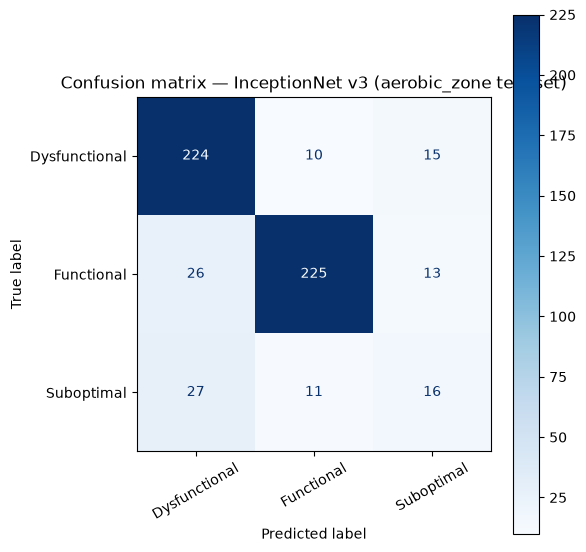

               precision    recall  f1-score   support

Dysfunctional      0.809     0.900     0.852       249
   Functional      0.915     0.852     0.882       264
   Suboptimal      0.364     0.296     0.327        54

     accuracy                          0.820       567
    macro avg      0.696     0.683     0.687       567
 weighted avg      0.816     0.820     0.816       567



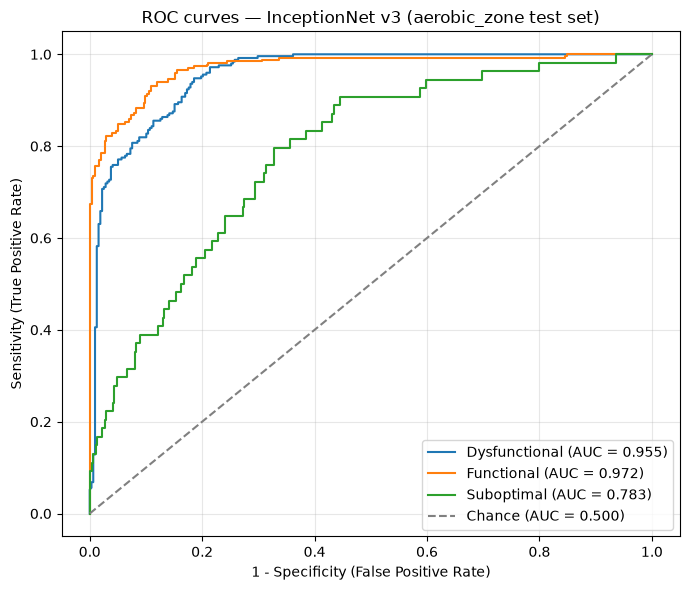

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.955
  Functional     : 0.972
  Suboptimal     : 0.783

Mean AUC (over 3/3 classes with test examples): 0.903


(np.float64(0.8201058201058201),
 {'Dysfunctional': 0.9549076810386199,
  'Functional': 0.9716721672167216,
  'Suboptimal': 0.7834813370875748})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "InceptionNet v3", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("InceptionNet v3", "inception_v3")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_inception_v3_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_inception_v3_chronological.pt
